# Real-vs-fake discriminator: GeoLife Beijing traces

A classifier two-sample test (`docs/realfake/geolife.md`, decision D8): a model is trained to tell
k-point windows of real Beijing traces (label 0) from windows of the synthetic variant
`outings_v2_seed0` (label 1). AUC 0.5 means indistinguishable at this level, 1.0 trivially
detectable. Identifiers, absolute dates and absolute lon/lat never enter the features; train and
test users are disjoint. Results read from `geolife/eval/results/discriminator/` (map features on)
and `discriminator_nomap/`; the SNAP counterpart is `snap/eval/notebooks/viz_discriminator.ipynb`.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline
warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "geolife").exists())
sys.path.insert(0, str(ROOT / "src"))
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
RES = ROOT / "geolife" / "eval" / "results"
runs = {"map on": RES / "discriminator", "no map": RES / "discriminator_nomap"}
summ = {k: pd.read_csv(d / "discriminator_summary.csv") for k, d in runs.items()}
imp  = {k: pd.read_csv(d / "discriminator_importance.csv") for k, d in runs.items()}
size = {k: pd.read_csv(d / "discriminator_by_size.csv") for k, d in runs.items()}

## 1. Headline: can a classifier tell the traces apart?

Mean test AUC over the 3 user-disjoint folds, against the two controls that make the number
trustworthy: the real-vs-real AUC (one half of the real users against the other; must sit near 0.5)
and the label-permutation AUC (same folds, shuffled training labels).

,run,model,auc,auc_std,ci_lo,ci_hi,permuted,real_vs_real
0,map on,logreg,0.9830,0.0043,0.9781,0.9874,0.4691,0.5227
1,map on,gbm,0.9996,0.0001,0.9991,0.9999,0.4881,0.4841
2,no map,logreg,0.9808,0.0043,0.9754,0.9857,0.4616,0.5325
3,no map,gbm,0.9995,0.0001,0.9991,0.9998,0.4805,0.4723


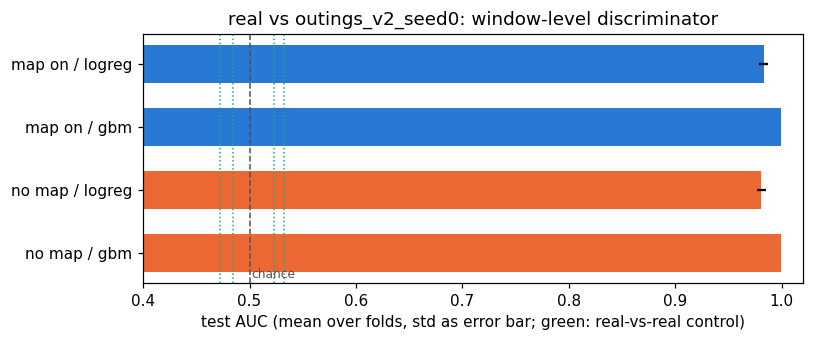

In [2]:
rows = []
for k, s in summ.items():
    m = s[s.method != "real_vs_real"]
    for _, r in m.iterrows():
        rows.append({"run": k, "model": r["model"], "auc": r["auc_mean"], "auc_std": r["auc_std"],
                     "ci_lo": r["auc_lo_mean"], "ci_hi": r["auc_hi_mean"],
                     "permuted": r["permuted_auc_mean"], "real_vs_real": r["real_vs_real_auc_mean"]})
hl = pd.DataFrame(rows)
display(hl.round(4))
fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(hl))
ax.barh(y, hl["auc"], xerr=hl["auc_std"], color=["#2a78d6" if r == "map on" else "#eb6834" for r in hl["run"]], height=0.6)
ax.set_yticks(y); ax.set_yticklabels(hl["run"] + " / " + hl["model"]); ax.invert_yaxis()
ax.axvline(0.5, color="#52514e", lw=1, ls="--"); ax.text(0.502, len(hl) - 0.6, "chance", fontsize=8, color="#52514e")
for ctrl in hl["real_vs_real"].unique():
    ax.axvline(ctrl, color="#1baf7a", lw=1, ls=":")
ax.set_xlim(0.4, 1.02); ax.set_xlabel("test AUC (mean over folds, std as error bar; green: real-vs-real control)")
ax.set_title("real vs outings_v2_seed0: window-level discriminator")
plt.tight_layout()

**What we see (2026-11-03 run).** The generator is still trivially detectable at the window
level: gbm AUC 0.9996 with map features and 0.9995 without, logreg 0.983/0.981 - against clean
controls (real-vs-real 0.47-0.53, permuted 0.46-0.49). Dropping the whole map group does not move
the headline, so the separation is NOT coming from where the traces sit on the map: it is in the
traces themselves. This mirrors SNAP (gbm 0.9994-0.9999 there): the artifact matches the histograms
it releases, and the classifier finds what the released tables do not constrain.

## 2. Which feature groups carry the separation

Grouped permutation importance (all columns of a group shuffled together, 5 repeats, fold 0,
strongest model): AUC drop when the group is destroyed.

run,map on,no map
group,,
kinematics,0.0584,0.0606
map,0.0001,NaN
sampling,0.2578,0.2658
shape,0.0002,0.0001
stops,0.0000,0.0000
time,0.0000,-0.0000


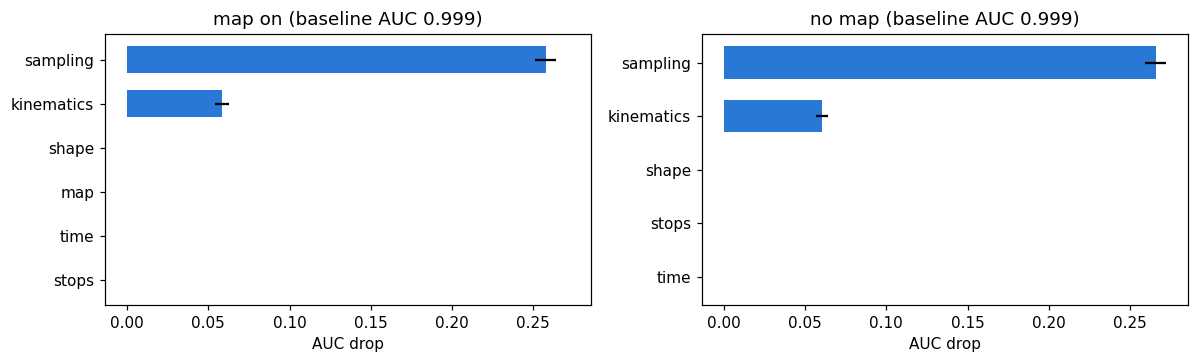

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for ax, (k, df) in zip(axes, imp.items()):
    d = df.sort_values("auc_drop", ascending=True)
    ax.barh(d["group"], d["auc_drop"], xerr=d.get("auc_drop_std"), color="#2a78d6", height=0.6)
    ax.set_title(f"{k} (baseline AUC {d['auc_baseline'].iloc[0]:.3f})"); ax.set_xlabel("AUC drop")
plt.tight_layout()
display(pd.concat([df.assign(run=k) for k, df in imp.items()])
        .pivot_table(index="group", columns="run", values="auc_drop").round(4))

**What we see.** `sampling` dominates in both runs (drop 0.258 with map / 0.266 without) with
`kinematics` a clear second (0.058 / 0.061); `shape`, `stops`, `time` and `map` are all <= 0.0002.
Note the grouped drops do not add up to AUC-0.5: the signal is redundant across groups (destroying
one still leaves the others enough). The sampling texture (the dt sequence) and the step kinematics
are the generator's fingerprint; the DP sensor tables match marginal histograms, but not the joint
texture a window exposes.

## 3. AUC by window size

Smaller windows carry less evidence; if the AUC stayed high at k=30 the tell would be per-point, if
it only emerged at k=600 it would be a long-range property.

,run,lo,hi,n,auc
0,map on,30.0,60.0,560,0.998
1,map on,60.0,120.0,484,1.000
2,map on,120.0,240.0,431,1.000
3,map on,240.0,480.0,419,1.000
4,map on,480.0,601.0,114,1.000
0,no map,30.0,60.0,560,0.997
1,no map,60.0,120.0,484,1.000
2,no map,120.0,240.0,431,1.000
3,no map,240.0,480.0,419,1.000
4,no map,480.0,601.0,114,1.000


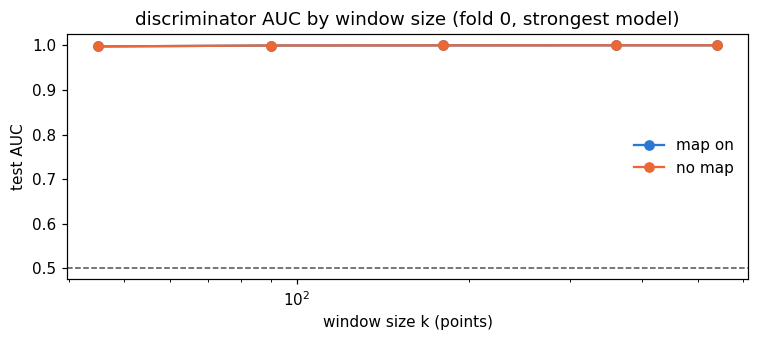

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for (k, df), c in zip(size.items(), ["#2a78d6", "#eb6834"]):
    mid = (df["lo"] + df["hi"]) / 2
    ax.plot(mid, df["auc"], "o-", color=c, label=k)
ax.set_xscale("log"); ax.axhline(0.5, color="#52514e", lw=1, ls="--")
ax.set_xlabel("window size k (points)"); ax.set_ylabel("test AUC"); ax.legend(frameon=False)
ax.set_title("discriminator AUC by window size (fold 0, strongest model)")
plt.tight_layout()
display(pd.concat([df.assign(run=k) for k, df in size.items()])[["run", "lo", "hi", "n", "auc"]].round(3))

**What we see.** Detection is near-certain even for the smallest windows (AUC 0.997-0.998 at
k 30-60, 1.000 above): 30 points - about a minute of trace - already give it away. The tell is
local, per-step texture, not a long-range trajectory property - consistent with the
sampling/kinematics importance.

## 4. Per-feature separators

The committed tables stop at group level. Here the per-feature view, computed once on a fresh
dataset (same loaders, sampler and featurizer as the run; 2000 windows per class, map features
included, user-disjoint split):

* **single-feature AUC**: each feature alone as a ranking score (flipped to >= 0.5), on the test
  windows - "how far does this one number get you";
* **per-feature permutation importance**: AUC drop of the fitted gbm when one feature is shuffled -
  "what does the model actually lean on" (small drops everywhere = redundant signal, as on SNAP).

In [5]:
from geolife.eval.discriminator import TraceFeaturizer, WindowSampler, load_real_arrays, load_synthetic_arrays
from geolife.eval.discriminate import road_cells
from realfake.dataset import build_dataset
from realfake.importance import permutation_importance
from realfake.metrics import auc
from realfake.models import MODELS
from realfake.split import group_split

real = load_real_arrays(ROOT / "geolife/inside/data/points.parquet")
fake = load_synthetic_arrays(ROOT / "geolife/outside/synthetic/outings_v2_seed0")
places = pd.read_parquet(ROOT / "geolife/outside/cache/places_beijing_big.parquet")
cells = road_cells(ROOT / "geolife/outside/cache")
feat = TraceFeaturizer(places_latlon=places[["lat", "lon"]].to_numpy(), road_cells=cells)
ds = build_dataset(real, [("seed0", fake)], WindowSampler(), feat, n=2000, seed=0)
train, test = group_split(ds.groups, test_frac=0.25, seed=0, y=ds.y)
gbm = MODELS["gbm"](ds.x[train], ds.y[train], seed=0)
print(f"dataset {ds.x.shape}, test AUC {auc(gbm.scores(ds.x[test]), ds.y[test]):.4f}")

dataset (4000, 67), test AUC 0.9993


,single_auc,perm_drop
feature,,
kinematics:thin30_step_q90,0.8173,0.0000
kinematics:thin30_speed_q90,0.8149,0.0000
kinematics:raw_speed_q90,0.8071,0.0004
kinematics:thin30_speed_log_std,0.7962,0.0003
kinematics:raw_speed_q75,0.7891,0.0001
kinematics:thin30_speed_q75,0.7876,0.0000
kinematics:thin30_accel_abs_q90,0.7719,0.0000
kinematics:raw_step_q90,0.7551,0.0000
kinematics:raw_speed_log_std,0.7504,-0.0001


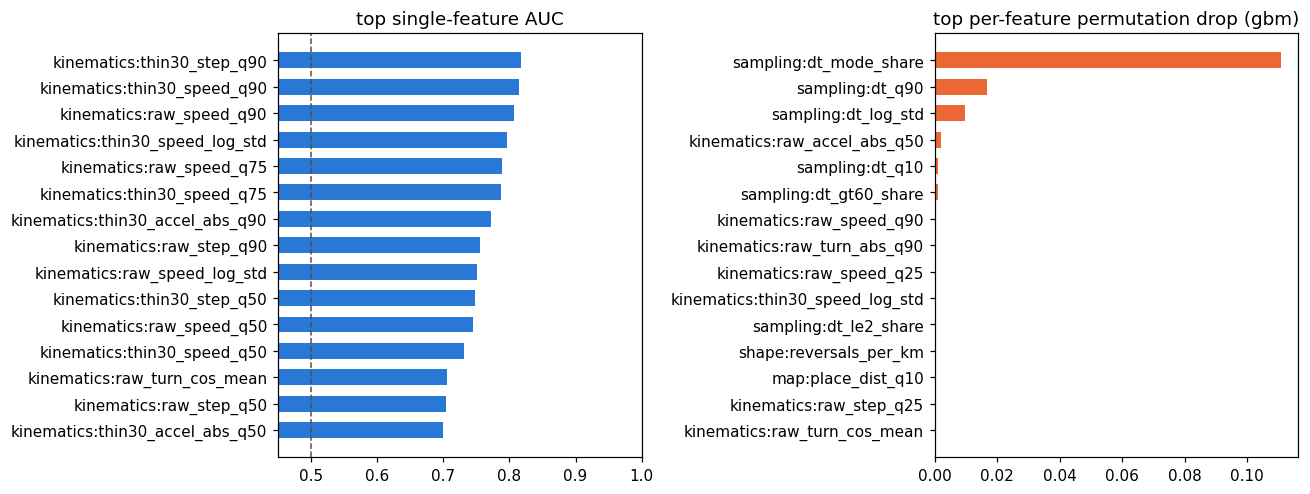

In [6]:
xt, yt = ds.x[test], ds.y[test]
uni = np.array([max(a := auc(xt[:, j], yt), 1 - a) for j in range(xt.shape[1])])
per = permutation_importance(gbm, xt, yt, ds.feature_names, {f: [f] for f in ds.feature_names}, seed=0)
per = per.rename(columns={"group": "feature"}).set_index("feature")
tab = pd.DataFrame({"feature": ds.feature_names, "single_auc": uni}).set_index("feature")
tab["perm_drop"] = per["auc_drop"]
tab = tab.sort_values("single_auc", ascending=False)
display(tab.head(20).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
top = tab.head(15).iloc[::-1]
axes[0].barh(top.index, top["single_auc"], color="#2a78d6", height=0.6)
axes[0].axvline(0.5, color="#52514e", lw=1, ls="--"); axes[0].set_xlim(0.45, 1.0)
axes[0].set_title("top single-feature AUC")
topp = tab.sort_values("perm_drop", ascending=False).head(15).iloc[::-1]
axes[1].barh(topp.index, topp["perm_drop"], color="#eb6834", height=0.6)
axes[1].set_title("top per-feature permutation drop (gbm)")
plt.tight_layout()

## 5. How the top separators differ

ECDFs of the strongest single features, real (black) vs synthetic (orange), over the test windows -
the direction of each gap says what the generator should fix.

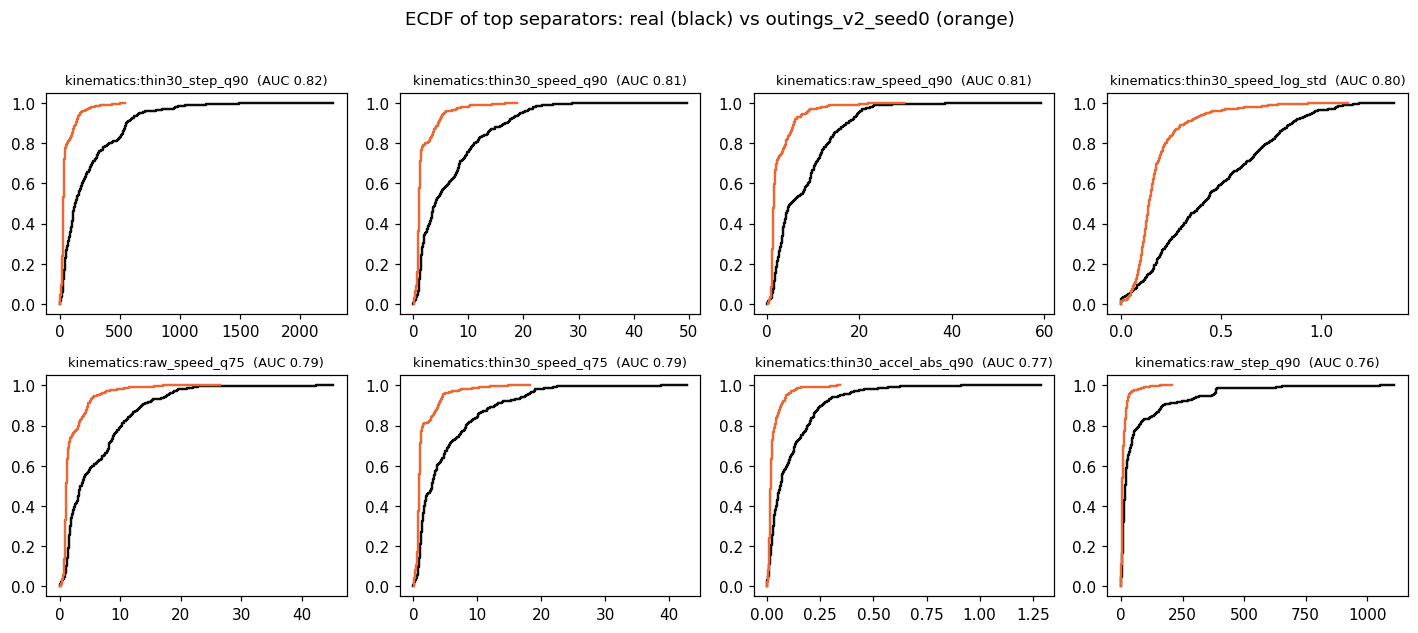

In [7]:
top8 = tab.head(8).index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(13, 5.6))
for ax, f in zip(axes.ravel(), top8):
    j = ds.feature_names.index(f)
    for lab, c in ((0, "#0b0b0b"), (1, "#eb6834")):
        v = np.sort(xt[yt == lab, j])
        ax.step(v, np.linspace(0, 1, len(v)), color=c, lw=1.6)
    ax.set_title(f"{f}  (AUC {tab.loc[f, 'single_auc']:.2f})", fontsize=8.5)
fig.suptitle("ECDF of top separators: real (black) vs outings_v2_seed0 (orange)", y=1.02)
plt.tight_layout()

**What we see (the separator list, 2026-11-03).** Two findings, one per column:

1. **The best single separators are the upper-tail kinematics - the synthetic traces are now too
   SLOW and too uniform.** Top single-feature AUCs are `kinematics:thin30_step_q90` (0.82),
   `thin30_speed_q90` (0.81), `raw_speed_q90` (0.81), `thin30_speed_log_std` (0.80): the real 90th
   percentile of 30s-thinned speed sits around 4.0 m/s per window median, the synthetic at 1.0; raw
   step q90 18 m vs 5.9 m; speed variability (log-std) is half the real value. This is the
   overcorrection of the old baseline (which was 2.7x too FAST at 13.5 m/s): the inverse-CDF
   rendering pinned speeds near the fitted walk median and lost both the fast tail (vehicle
   segments) and the within-outing speed spread.
2. **The model itself leans on the dt texture.** The only feature with a material per-feature
   permutation drop is `sampling:dt_mode_share` (0.111; next are `dt_q90` 0.017 and `dt_log_std`
   0.010): rendered windows concentrate too tightly on the per-user modal interval - real GeoLife dt
   sequences are ragged mixtures with bursts and stragglers, even though the dt *histogram* matches
   the released table. All kinematics drops are ~0 despite single AUCs of 0.7-0.8: the signal is
   massively redundant (gbm can rebuild it from the dt features alone), exactly the SNAP pattern -
   the generator problem is a texture, not one knob.

`map:place_dist_q90/q50` separate at 0.70/0.66 alone (synthetic points hug the public places) but
the model never needs them - consistent with the near-zero map group drop in section 2.

**What this suggests for the generator (PLAN candidates):** (i) restore the speed scale and spread -
per-mode speeds with within-outing variation, not a single pinned median (check the seed0
`sensor_speed` fallback: its signal was 1.9 < 3.0, so seed0 renders from defaults); (ii) render dt
as a process (burst/jitter mixture around the sampled interval), not near-constant draws; (iii) the
map group can be deprioritised - it separates barely and the model ignores it.

## 6. Pointers

Full tables: `geolife/eval/results/discriminator{,_nomap}/discriminator*.{csv,json}`. Design and the
dropped-by-construction list: `docs/realfake/geolife.md` (D8). SNAP counterpart and its findings:
`docs/realfake/snap.md`, `snap/eval/notebooks/viz_discriminator.ipynb`. Acceptance criteria once the
generator improves: controls near 0.5 first, then AUC toward the real-vs-real floor.